# Ordenamiento por Seleccion en 3D
Ejecuta las celdas en orden. La siguiente celda instala Matplotlib e ipympl en el kernel actual.

In [1]:
%pip install matplotlib ipympl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
%matplotlib widget
import matplotlib.pyplot as plt
plt.ioff()

In [3]:
"""
Visualizador 3D de Ordenamiento por Selección (matplotlib).

Funciona igual en:
  * Script de Python:   python selection_sort_viz.py
  * Jupyter Notebook:   %matplotlib widget   (requiere: pip install ipympl)
                        viz = iniciar()
"""
import random
import re

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.widgets import Button, Slider

# --------------------------------------------------------------------------
# Código que se muestra en el panel (la línea resaltada = línea en ejecución)
# --------------------------------------------------------------------------
CODIGO = [
    "def selection_sort(lista):",
    "    for inicio in range(len(lista) - 1):",
    "        minimo = inicio",
    "        for comparando in range(inicio + 1, len(lista)):",
    "            if lista[comparando] < lista[minimo]:",
    "                minimo = comparando",
    "        lista[inicio], lista[minimo] = lista[minimo], lista[inicio]",
    "    return lista",
]

# Colores
BG = "#2b2b2b"
AZUL = "#1e88ff"
ROJO = "#ff1a1a"        # posición 'inicio'
AMARILLO = "#ffd600"    # mínimo actual
NARANJA = "#ff9800"     # elemento que se está comparando
VERDE = "#43a047"       # ya ordenado
RESALTADO = "#e6b800"

KEYWORDS = {"def", "for", "in", "if", "return"}
BUILTINS = {"range", "len"}


# --------------------------------------------------------------------------
# Generación de pasos
# --------------------------------------------------------------------------
def generar_pasos(datos):
    """Ejecuta selection sort y guarda una 'foto' por cada línea ejecutada."""
    a = list(datos)
    n = len(a)
    pasos = []

    def foto(linea, inicio=None, minimo=None, comp=None, ordenadas=0):
        pasos.append(dict(arr=list(a), linea=linea, inicio=inicio,
                          minimo=minimo, comp=comp, ordenadas=ordenadas))

    for inicio in range(n - 1):
        foto(1, inicio, None, None, inicio)                       # for inicio...
        minimo = inicio
        foto(2, inicio, minimo, None, inicio)                     # minimo = inicio
        for comp in range(inicio + 1, n):
            foto(3, inicio, minimo, comp, inicio)                 # for comparando...
            foto(4, inicio, minimo, comp, inicio)                 # if ... <
            if a[comp] < a[minimo]:
                minimo = comp
                foto(5, inicio, minimo, comp, inicio)             # minimo = comparando
        a[inicio], a[minimo] = a[minimo], a[inicio]
        foto(6, inicio, minimo, None, inicio + 1)                 # intercambio
    foto(7, None, None, None, n)                                  # return lista
    return pasos


# --------------------------------------------------------------------------
# Visualizador
# --------------------------------------------------------------------------
class Visualizador:
    FS_CODIGO = 7

    def __init__(self, cantidad=15, semilla=None, ancho=900):
        self.rng = random.Random(semilla)
        self.cantidad = cantidad
        self.ancho_px = ancho
        self.datos = self._nuevos_datos(cantidad)
        self.pasos = generar_pasos(self.datos)
        self.paso = 1
        self._bloqueo = False
        self.reproduciendo = False

        self._construir_figura()
        self._dibujar()

    # ---------------------------------------------------------------- datos
    def _nuevos_datos(self, n):
        return [self.rng.randint(3, 20) for _ in range(n)]

    # --------------------------------------------------------------- figura
    def _construir_figura(self):
        ancho_pulgadas = self.ancho_px / 100
        self.fig = plt.figure(figsize=(ancho_pulgadas, ancho_pulgadas * 0.68), facecolor=BG)
        self.fig.canvas.layout.width = f"{self.ancho_px}px"
        self.fig.canvas.layout.height = "620px"
        self.titulo = self.fig.text(0.32, 0.965, "", color="white",
                                    fontsize=18, ha="center")

        # Eje 3D
        self.ax3d = self.fig.add_axes([-0.005, 0.035, 0.60, 0.87],
                                      projection="3d", facecolor=BG)
        self.elev, self.azim = 24, -88
        self.ax3d.view_init(elev=self.elev, azim=self.azim)

        # Panel de código
        self.ax_code = self.fig.add_axes([0.590, 0.48, 0.390, 0.40],
                                         facecolor="black")
        ancho_pt = 0.390 * ancho_pulgadas * 72
        self.charw_pt = 0.602 * self.FS_CODIGO
        self.ncols = ancho_pt / self.charw_pt
        for s in self.ax_code.spines.values():
            s.set_edgecolor("#111")
        self.ax_code.set_xticks([])
        self.ax_code.set_yticks([])

        # Sliders
        ax_c = self.fig.add_axes([0.77, 0.405, 0.20, 0.022], facecolor=BG)
        self.sl_cant = Slider(ax_c, "Cantidad: 15", 5, 15, valinit=self.cantidad,
                              valstep=1, color="#5b9bd5", initcolor="none")
        self.sl_cant.valtext.set_visible(False)
        self._estilo_slider(self.sl_cant)

        ax_p = self.fig.add_axes([0.745, 0.305, 0.19, 0.022], facecolor=BG)
        self.sl_paso = Slider(ax_p, "Paso:", 1, len(self.pasos), valinit=1,
                              valstep=1, color="#888888", initcolor="none")
        self._estilo_slider(self.sl_paso)

        # Botones
        def boton(x, y, texto):
            ax = self.fig.add_axes([x, y, 0.095, 0.055])
            b = Button(ax, texto, color="#333333", hovercolor="#4a4a4a")
            b.label.set_color("white")
            b.label.set_fontsize(9)
            for s in ax.spines.values():
                s.set_edgecolor("#111")
            return b

        xs = [0.645, 0.755, 0.865]
        self.b5 = boton(xs[0], 0.185, "Usar 5")
        self.b15 = boton(xs[1], 0.185, "Usar 15")
        self.b_ini = boton(xs[2], 0.185, "Iniciar")
        self.b_ant = boton(xs[0], 0.095, "Anterior")
        self.b_sig = boton(xs[1], 0.095, "Siguiente")
        self.b_rep = boton(xs[2], 0.095, "Reproducir")

        self.b5.on_clicked(lambda e: self._set_cantidad(5))
        self.b15.on_clicked(lambda e: self._set_cantidad(15))
        self.b_ini.on_clicked(self._iniciar_animacion)
        self.b_ant.on_clicked(lambda e: self._ir_a(self.paso - 1))
        self.b_sig.on_clicked(lambda e: self._ir_a(self.paso + 1))
        self.b_rep.on_clicked(self._toggle_play)
        self.sl_cant.on_changed(self._on_cantidad)
        self.sl_paso.on_changed(self._on_paso)

        # Leyenda
        leyenda = [(ROJO, "inicio"), (NARANJA, "comparando"),
                   (AMARILLO, "mínimo"), (VERDE, "ordenado")]
        x = 0.06
        for color, texto in leyenda:
            self.fig.patches.append(Rectangle((x, 0.045), 0.012, 0.02,
                                              transform=self.fig.transFigure,
                                              facecolor=color, edgecolor="black"))
            self.fig.text(x + 0.017, 0.05, texto, color="white", fontsize=8)
            x += 0.12

        # Timer para la animación
        self.timer = self.fig.canvas.new_timer(interval=180)
        self.timer.add_callback(self._tick)

    @staticmethod
    def _estilo_slider(sl):
        sl.label.set_color("white")
        sl.label.set_fontsize(12)
        sl.valtext.set_color("white")
        sl.valtext.set_fontsize(12)
        sl.ax.set_xticks([])
        sl.ax.set_yticks([])
        for s in sl.ax.spines.values():
            s.set_visible(False)
        if hasattr(sl, "track"):
            sl.track.set_facecolor("#aaaaaa")
        h = getattr(sl, "_handle", None) or getattr(sl, "handle", None)
        if h is not None:
            h.set_markersize(16)
            h.set_markerfacecolor("white")
            h.set_markeredgecolor("#777777")

    # -------------------------------------------------------------- dibujo
    def _colores(self, p):
        cols = []
        for i in range(len(p["arr"])):
            c = AZUL
            if i < p["ordenadas"]:
                c = VERDE
            if i == p["comp"]:
                c = NARANJA
            if i == p["minimo"]:
                c = AMARILLO
            if i == p["inicio"]:
                c = ROJO
            cols.append(c)
        return cols

    def _dibujar_3d(self, p):
        ax = self.ax3d
        # conservar la rotación que el usuario haya dado con el ratón
        self.elev, self.azim = ax.elev, ax.azim
        ax.cla()
        ax.set_facecolor(BG)
        ax.set_axis_off()

        arr = p["arr"]
        n = len(arr)
        ancho = 0.38
        ax.bar3d(range(n), [0] * n, [0] * n, ancho, ancho, arr,
                 color=self._colores(p), edgecolor="black",
                 linewidth=1.2, shade=True)

        # etiquetas con el valor
        for i, v in enumerate(arr):
            ax.text(i + ancho / 2, ancho / 2, v + 0.6, str(v),
                    color="white", fontsize=7, ha="center", va="bottom")

        # rejilla en el suelo
        x0, x1, y0, y1 = -1, n + 0.5, -2, 5
        for x in range(x0, int(x1) + 1):
            ax.plot([x, x], [y0, y1], [0, 0], color="#777", lw=0.5)
        for k in range(8):
            y = y0 + k * (y1 - y0) / 7
            ax.plot([x0, x1], [y, y], [0, 0], color="#777", lw=0.5)

        ax.set_xlim(x0, x1)
        ax.set_ylim(y0, y1)
        ax.set_zlim(0, 24)
        ax.set_box_aspect((n + 1, 4.5, 9))
        ax.view_init(elev=self.elev, azim=self.azim)

    def _dibujar_codigo(self, linea):
        ax = self.ax_code
        ax.cla()
        ax.set_facecolor("black")
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_xlim(0, self.ncols)
        ax.set_ylim(len(CODIGO) + 0.4, -0.4)

        ax.add_patch(Rectangle((0, linea + 0.02), self.ncols, 0.96,
                               facecolor=RESALTADO, edgecolor="none"))

        for i, texto in enumerate(CODIGO):
            activo = (i == linea)
            ax.text(0.20, i + 0.5, str(i + 1), color="#555" if not activo else "#7a5c00",
                    fontsize=self.FS_CODIGO, family="monospace", va="center")
            col = 3.0
            for m in re.finditer(r"\w+|\s+|.", texto):
                tok = m.group()
                color = "#d6dcff"
                if tok in KEYWORDS:
                    color = "#7aa2f7"
                elif tok in BUILTINS:
                    color = "#e0af68"
                elif tok.isdigit():
                    color = "#ff9e64"
                elif texto.startswith("def") and tok == "selection_sort":
                    color = "#e0af68"
                if activo:
                    color = "#1a1a1a"
                ax.text(col, i + 0.5, tok, color=color, fontsize=self.FS_CODIGO,
                        family="monospace", va="center")
                col += len(tok)

    def _dibujar(self):
        total = len(self.pasos)
        p = self.pasos[self.paso - 1]
        self.titulo.set_text(f"Paso {self.paso}/{total} - Ordenamiento por Selección")
        self._dibujar_3d(p)
        self._dibujar_codigo(p["linea"])
        self.fig.canvas.draw_idle()

    # ----------------------------------------------------------- callbacks
    def _actualizar_sliders(self):
        self._bloqueo = True
        total = len(self.pasos)
        self.sl_paso.valmax = total
        self.sl_paso.ax.set_xlim(1, total)
        self.sl_paso.set_val(self.paso)
        self.sl_cant.set_val(self.cantidad)
        self.sl_cant.label.set_text(f"Cantidad: {self.cantidad}")
        self._bloqueo = False

    def _regenerar(self, n, nuevos=True):
        self._detener()
        self.cantidad = n
        if nuevos:
            self.datos = self._nuevos_datos(n)
        self.pasos = generar_pasos(self.datos)
        self.paso = 1
        self._actualizar_sliders()
        self._dibujar()

    def _on_cantidad(self, val):
        if self._bloqueo:
            return
        self._regenerar(int(val))

    def _set_cantidad(self, n):
        self._regenerar(n)

    def _on_paso(self, val):
        if self._bloqueo:
            return
        self.paso = int(val)
        self._dibujar()

    def _ir_a(self, paso):
        paso = max(1, min(len(self.pasos), paso))
        self.paso = paso
        self._bloqueo = True
        self.sl_paso.set_val(paso)
        self._bloqueo = False
        self._dibujar()

    def _iniciar_animacion(self, _evt=None):
        self._regenerar(self.cantidad)
        self._reproducir()

    def _toggle_play(self, _evt=None):
        if self.reproduciendo:
            self._detener()
        else:
            if self.paso >= len(self.pasos):
                self._ir_a(1)
            self._reproducir()

    def _reproducir(self):
        self.reproduciendo = True
        self.b_rep.label.set_text("Pausar")
        self.timer.start()

    def _detener(self):
        self.reproduciendo = False
        self.timer.stop()
        self.b_rep.label.set_text("Reproducir")
        self.fig.canvas.draw_idle()

    def _tick(self):
        if self.paso >= len(self.pasos):
            self._detener()
            return
        self._ir_a(self.paso + 1)


# --------------------------------------------------------------------------
def iniciar(cantidad=15, semilla=None, ancho=900):
    """Crea y devuelve el visualizador. Guarda el resultado en una variable
    (viz = iniciar()) para que los widgets sigan activos."""
    return Visualizador(cantidad, semilla, ancho=ancho)


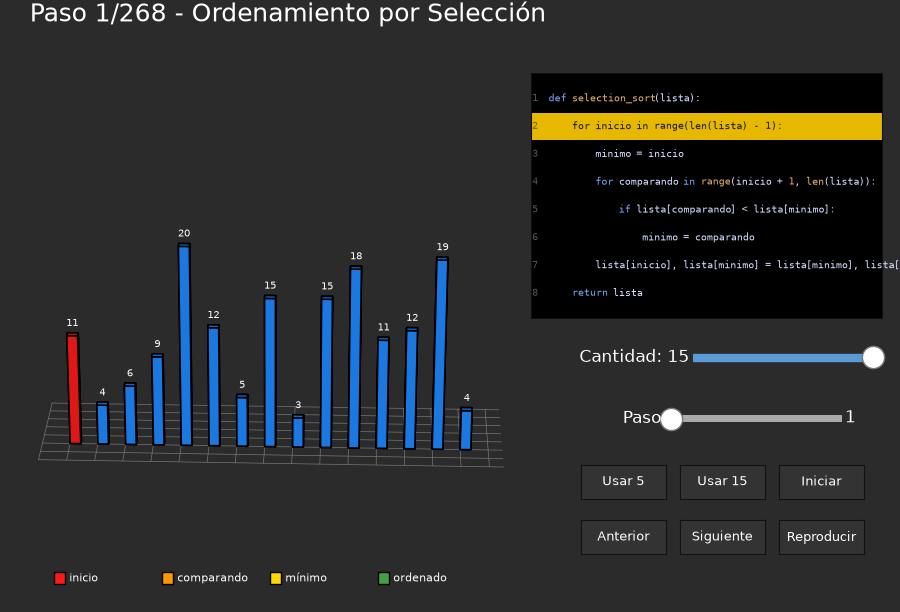

In [4]:
viz = iniciar(15, ancho=900)  # figura compacta
viz.fig.canvas